# 02 信道与 BER

使用自主实现的调制映射与解调解映射，补全 BER 扫描和绘图，对比 QPSK、8-PSK、16-QAM 在 AWGN 与 Rayleigh 信道下的误码性能。

In [1]:
# 导入依赖并准备调制、解调和 BER 统计的通用函数。
from pathlib import Path
import sys

# 从当前目录向上查找 src/sionna（若使用仓库源码则优先使用）。
for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "src" / "sionna").exists():
        sys.path.insert(0, str(p / "src"))
        break

import numpy as np
import torch
import matplotlib.pyplot as plt

# 设置 Matplotlib 中文字体，避免图标题和坐标轴中文乱码。
plt.rcParams["font.sans-serif"] = [
    "Microsoft YaHei",
    "SimHei",
    "Noto Sans CJK SC",
    "Arial Unicode MS",
    "DejaVu Sans",
]
plt.rcParams["axes.unicode_minus"] = False

# Word 报告中的图宽约 14.4 cm，而画布按英寸设置，插入时会被缩放，
# 因此把 matplotlib 的字号整体放大，使打印后的字号与正文（10.5 pt）接近。
plt.rcParams.update(
    {
        "font.size": 13,
        "axes.labelsize": 13,
        "axes.titlesize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "figure.dpi": 200,
        "savefig.dpi": 200,
    }
)

# 信道部分使用 Sionna 模块，星座映射与解映射由本实验自主实现（类似 16QAM 示例）。
from sionna.phy.channel import AWGN, RayleighBlockFading

# 固定使用 CPU，保证没有 GPU 的学生电脑也能运行。
DEVICE = "cpu"
PRECISION = "single"

# 固定随机种子，便于复现实验结果。
# 注意：Sionna 的 AWGN / 衰落信道使用自己的 torch.Generator（config.torch_rng），
# 因此除了 torch / numpy 之外还必须设置 sionna.phy.config.seed，否则噪声每次运行都不同。
from sionna.phy import config as sionna_config


def set_seed(seed=7):
    """固定 Python / NumPy / PyTorch / Sionna 四个随机源，使仿真结果可复现。"""
    torch.manual_seed(seed)
    np.random.seed(seed)
    sionna_config.seed = int(seed)


set_seed(7)

# 图、数据输出目录：便于把过程性与结果性材料归档到同一文件夹。
FIG_DIR = Path.cwd() / "figures"
DATA_DIR = Path.cwd() / "data"
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)


# 将 Eb/N0 转成 AWGN 模块需要的噪声功率谱密度 no。
def ebno_db_to_no(ebno_db, nbits, coderate=1.0):
    ebno = 10 ** (torch.as_tensor(ebno_db, dtype=torch.float32, device=DEVICE) / 10.0)
    return 1.0 / (ebno * nbits * coderate)


# 统计误比特数，BER 会在此基础上除以总 bit 数。
def count_bit_errors(b, b_hat):
    # 统一转成 int32 后逐元素比较，统计不同 bit 的个数。
    return int(torch.sum(b.to(torch.int32) != b_hat.to(torch.int32)).item())


def ber(b, b_hat):
    return count_bit_errors(b, b_hat) / b.numel()


# 生成各调制方式的星座表，BPSK/QPSK/16-QAM 归一化至平均符号能量 Es = 1。
def get_constellation(name):
    if name == "BPSK":
        # 1 bit: 0 -> -1, 1 -> +1
        pts = torch.tensor([-1.0 + 0j, 1.0 + 0j], dtype=torch.complex64, device=DEVICE)
    elif name == "QPSK":
        # 2 bit: 00, 01, 10, 11
        pts = torch.tensor(
            [1.0 + 1.0j, -1.0 + 1.0j, 1.0 - 1.0j, -1.0 - 1.0j],
            dtype=torch.complex64,
            device=DEVICE,
        ) / np.sqrt(2.0)
    elif name == "8-PSK":
        # 3 bit Gray 码映射: 相邻星座点仅相差 1 bit
        gray_order = [0, 1, 3, 2, 6, 7, 5, 4]
        angles = torch.zeros(8, dtype=torch.float32, device=DEVICE)
        for k, bit_val in enumerate(gray_order):
            angles[bit_val] = k * (2 * np.pi / 8)
        pts = torch.exp(1j * angles).to(torch.complex64)
    elif name == "16-QAM":
        # 4 bit 16-QAM 星座点（参考 16QAM/QAM_awgn.m）
        c16 = [
            1 + 1j,
            1 + 3j,
            3 + 1j,
            3 + 3j,
            -1 + 1j,
            -1 + 3j,
            -3 + 1j,
            -3 + 3j,
            -3 - 3j,
            -3 - 1j,
            -1 - 3j,
            -1 - 1j,
            1 - 1j,
            1 - 3j,
            3 - 1j,
            3 - 3j,
        ]
        pts = torch.tensor(c16, dtype=torch.complex64, device=DEVICE)
        es = torch.mean(torch.abs(pts) ** 2)
        pts = pts / torch.sqrt(es)
    else:
        raise ValueError(f"未知调制方式: {name}")
    return pts


# 类似 16QAM/modulation.m：将比特流按 nbits 查表映射到星座点
def modulate(bits, constell, nbits):
    # 把每个符号的 nbits 个比特视为一个 nbits 位二进制数（高位在前）作为星座索引。
    bits = bits.to(torch.int64)
    idx = torch.zeros(bits.shape[:-1], dtype=torch.long, device=DEVICE)
    for i in range(nbits):
        idx = (idx << 1) | bits[..., i]
    return constell[idx]


# 类似 16QAM/demodulation.m：基于最小欧氏距离判决解映射还原比特
def demodulate(rx_symbols, constell, nbits):
    # (..., 1) 与 (M,) 广播，得到接收符号到每个星座点的距离平方 (..., M)。
    dist = torch.abs(rx_symbols.unsqueeze(-1) - constell) ** 2
    idx = torch.argmin(dist, dim=-1)
    bits = torch.zeros(*idx.shape, nbits, dtype=torch.int32, device=DEVICE)
    for i in range(nbits):
        shift = nbits - 1 - i
        bits[..., i] = ((idx >> shift) & 1).to(torch.int32)
    return bits


In [2]:
# 封装 AWGN 与 Rayleigh 链路的 BER 扫描。
# AWGN 链路：发送信号直接叠加高斯白噪声。
def transmit_awgn(bits, constell, nbits, ebno_db):
    x = modulate(bits, constell, nbits)
    no = ebno_db_to_no(ebno_db, nbits)

    y = AWGN(precision=PRECISION, device=DEVICE)(x, no)

    return demodulate(y, constell, nbits)


# Rayleigh 链路：衰落信道加单抽头零陷均衡。
def transmit_rayleigh(bits, constell, nbits, ebno_db):
    x = modulate(bits, constell, nbits)
    no = ebno_db_to_no(ebno_db, nbits)

    # RayleighBlockFading 生成服从 CN(0,1) 的单径平坦衰落系数（块衰落）。
    ch = RayleighBlockFading(1, 1, 1, 1, precision=PRECISION, device=DEVICE)
    h, _ = ch(batch_size=x.numel(), num_time_steps=1)
    h = h.reshape(x.shape)

    # 接收端已知信道（理想 CSI），做单抽头迫零均衡 y / h。
    y = AWGN(precision=PRECISION, device=DEVICE)(h * x, no)
    y_eq = y / h

    return demodulate(y_eq, constell, nbits)


# 对 Eb/N0 列表扫描，返回一组 BER 曲线数值。
def simulate_ber(
    name, nbits, channel_type, ebno_db_list, batch_size=256, num_symbols=256
):
    constell = get_constellation(name)
    ber_list = []
    for ebno_db in ebno_db_list:
        # 每个 Eb/N0 点重新生成独立比特流，避免同一组比特重复统计。
        b = torch.randint(
            0, 2, (batch_size, num_symbols, nbits), dtype=torch.int32, device=DEVICE
        )

        if channel_type == "awgn":
            b_hat = transmit_awgn(b, constell, nbits, float(ebno_db))
        elif channel_type == "rayleigh":
            b_hat = transmit_rayleigh(b, constell, nbits, float(ebno_db))
        else:
            raise ValueError(f"未知信道类型: {channel_type}")

        ber_list.append(ber(b, b_hat))
    return np.array(ber_list)


图5  AWGN 与平坦瑞利衰落信道下三种调制的 BER 曲线


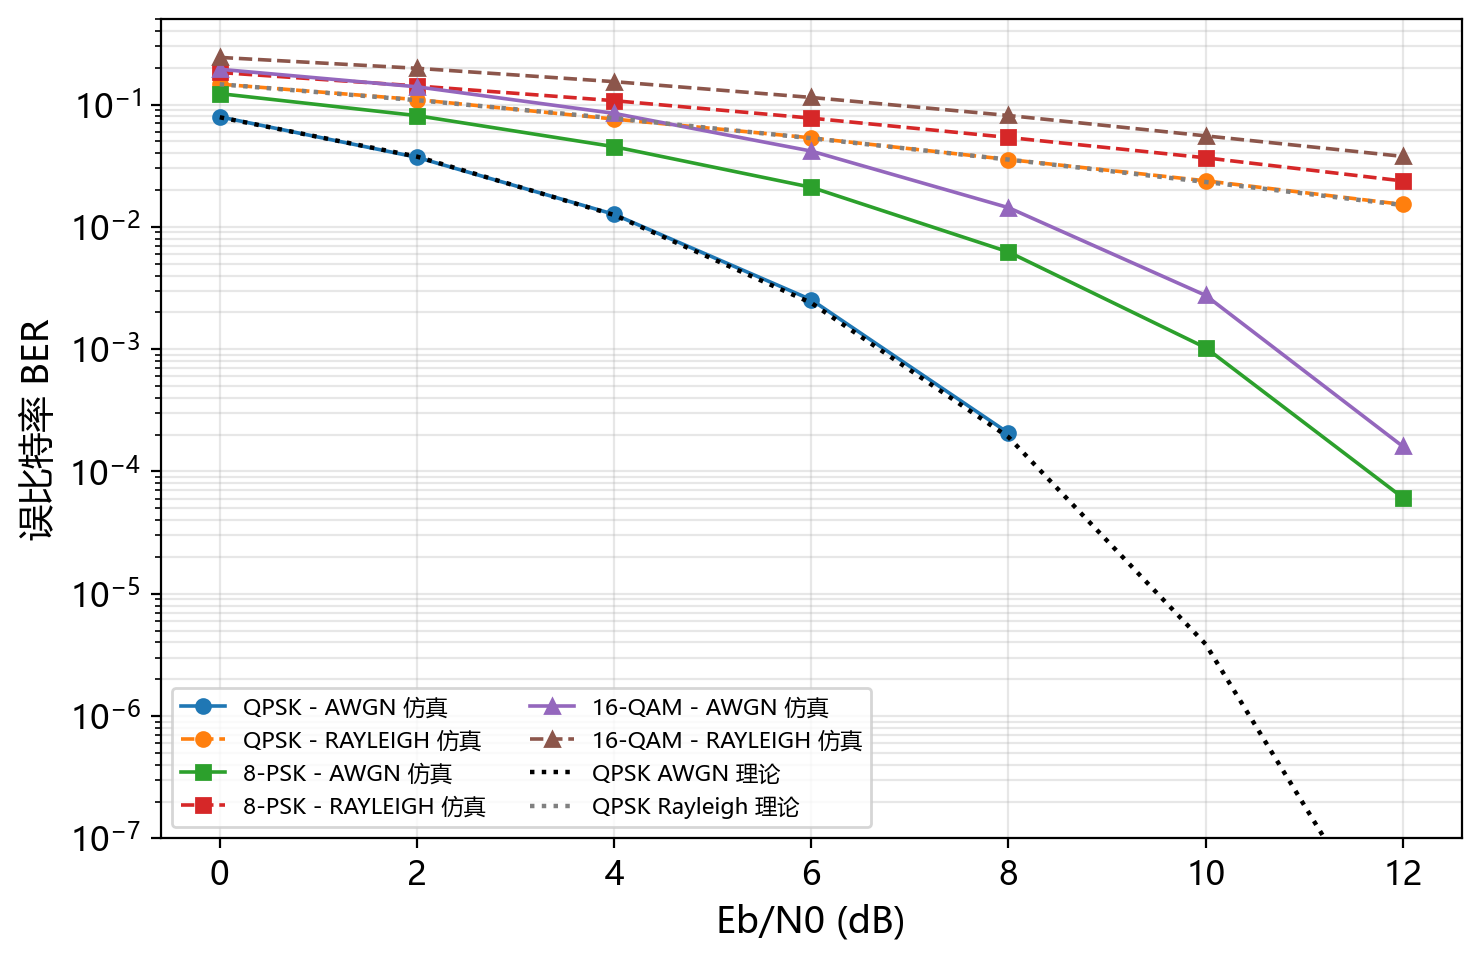

表 3  AWGN / Rayleigh 信道下各调制的 BER 仿真数据
 EbN0_dB  QPSK_awgn  QPSK_rayleigh  8-PSK_awgn  8-PSK_rayleigh  16-QAM_awgn  16-QAM_rayleigh
       0   0.079300       0.146751    0.122737        0.182714     0.194168         0.242714
       2   0.037003       0.109619    0.081116        0.141795     0.139553         0.197689
       4   0.012650       0.076019    0.045202        0.107437     0.084599         0.153732
       6   0.002533       0.053352    0.021047        0.077352     0.041607         0.114201
       8   0.000206       0.035500    0.006231        0.053767     0.014343         0.081303
      10   0.000000       0.023781    0.001027        0.036662     0.002750         0.055401
      12   0.000000       0.015244    0.000061        0.023712     0.000160         0.037659


In [3]:
# 扫描 Eb/N0，并把不同调制和信道的 BER 曲线画在同一张图中。
ebno_db = np.arange(0, 13, 2)

curves = {}

for name, nbits in {"QPSK": 2, "8-PSK": 3, "16-QAM": 4}.items():
    for ch in ["awgn", "rayleigh"]:
        curves[(name, ch)] = simulate_ber(name, nbits, ch, ebno_db)

# 理论基准：AWGN 信道下 QPSK/BPSK 的差错概率与单抽头瑞利信道下的理论 BER。
import scipy.special as sp

ebno_lin = 10.0 ** (ebno_db / 10.0)
theory_qpsk_awgn = 0.5 * sp.erfc(np.sqrt(ebno_lin))
theory_qpsk_rayleigh = 0.5 * (1.0 - np.sqrt(ebno_lin / (1.0 + ebno_lin)))

# 使用 semilogy 画出 6 条仿真 BER 曲线
fig, ax = plt.subplots(figsize=(7.6, 5.0))
styles = {
    ("QPSK", "awgn"): ("o", "-"),
    ("QPSK", "rayleigh"): ("o", "--"),
    ("8-PSK", "awgn"): ("s", "-"),
    ("8-PSK", "rayleigh"): ("s", "--"),
    ("16-QAM", "awgn"): ("^", "-"),
    ("16-QAM", "rayleigh"): ("^", "--"),
}
for key, values in curves.items():
    marker, ls = styles[key]
    # 高 SNR 下未统计到误码时 BER=0，绘制时用 NaN 断开曲线
    shown = [v if v > 0 else np.nan for v in values]
    ax.semilogy(
        ebno_db,
        shown,
        marker=marker,
        ls=ls,
        lw=1.3,
        ms=5,
        label=f"{key[0]} - {key[1].upper()} 仿真",
    )

ax.semilogy(ebno_db, theory_qpsk_awgn, color="k", ls=":", lw=1.6, label="QPSK AWGN 理论")
ax.semilogy(
    ebno_db, theory_qpsk_rayleigh, color="gray", ls=":", lw=1.6, label="QPSK Rayleigh 理论"
)

ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_ylim(1e-7, 0.5)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_ber_all_channels.png", dpi=200, bbox_inches="tight")
print("图5  AWGN 与平坦瑞利衰落信道下三种调制的 BER 曲线")
plt.show()

# 数值表（结果性数据）
import pandas as pd

df_curves = pd.DataFrame({"EbN0_dB": ebno_db})
for (name, ch), values in curves.items():
    df_curves[f"{name}_{ch}"] = values
print("表 3  AWGN / Rayleigh 信道下各调制的 BER 仿真数据")
print(df_curves.to_string(index=False))
df_curves.to_csv(DATA_DIR / "02_ber_curves.csv", index=False, encoding="utf-8-sig")

assert len(curves) == 6


## 补充：分信道对比与理论曲线

将 AWGN 与瑞利衰落两种信道分开展示，并叠加理论曲线，用于定量评估仿真与理论的吻合程度。


图6  AWGN 与瑞利衰落信道下仿真结果与理论曲线对比


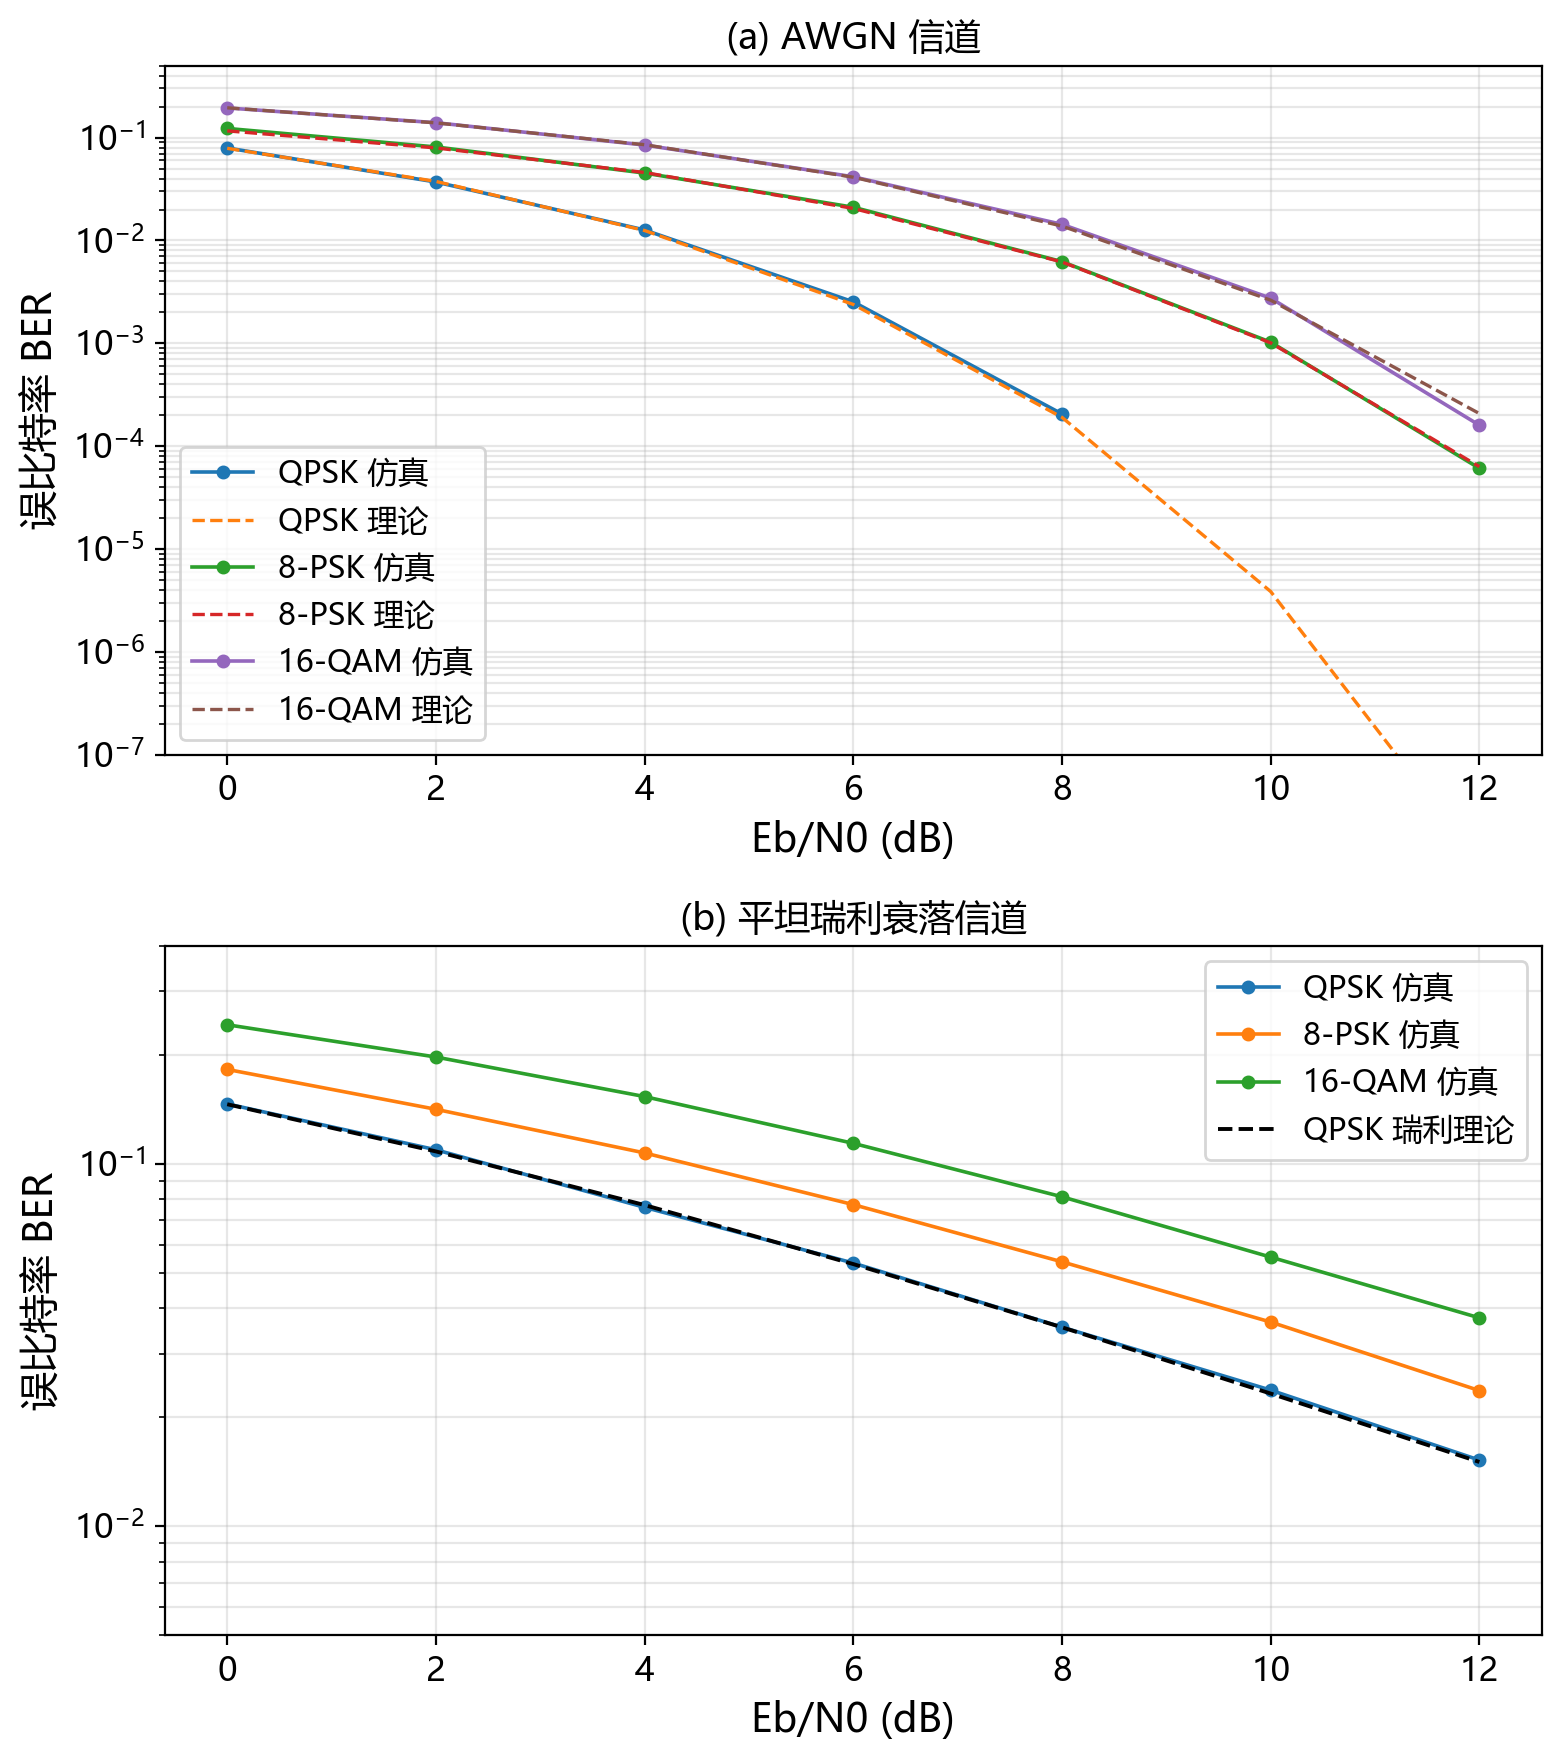

表 4  QPSK/AWGN 仿真 BER 相对理论值的偏差
  Eb/N0= 0 dB: 仿真=7.9300e-02  理论=7.8650e-02  相对偏差= 0.83%
  Eb/N0= 2 dB: 仿真=3.7003e-02  理论=3.7506e-02  相对偏差= 1.34%
  Eb/N0= 4 dB: 仿真=1.2650e-02  理论=1.2501e-02  相对偏差= 1.19%
  Eb/N0= 6 dB: 仿真=2.5330e-03  理论=2.3883e-03  相对偏差= 6.06%
  Eb/N0= 8 dB: 仿真=2.0599e-04  理论=1.9091e-04  相对偏差= 7.90%
  Eb/N0=10 dB: 仿真=0.0000e+00  理论=3.8721e-06  相对偏差=100.00%
  Eb/N0=12 dB: 仿真=0.0000e+00  理论=9.0060e-09  相对偏差=100.00%


In [4]:
# 补充扩展：分信道绘制，并与理论曲线逐点对比（便于在报告中讨论吻合程度）。
def _q(x):
    """高斯 Q 函数（与 scipy 的 erfc 等价写法）。"""
    return 0.5 * sp.erfc(np.asarray(x, dtype=np.float64) / np.sqrt(2.0))


def theory_16qam_exact(ebno_db):
    """按教材 16 点星座表的实际比特标注，对 AWGN 判决域做数值积分得到精确 BER。

    该表不是 Gray 排序（相邻点之间平均比特差大于 1），因此不能直接套用 Gray 编码的
    近似公式 3/8·erfc(√(2γb/5))，否则会低估约 1.4~1.6 倍；这里按判决域精确求和。
    """
    pts = get_constellation("16-QAM").cpu().numpy()
    levels = np.array([-3.0, -1.0, 1.0, 3.0]) / np.sqrt(10.0)
    bounds = [-np.inf, -2.0 / np.sqrt(10.0), 0.0, 2.0 / np.sqrt(10.0), np.inf]
    hamming = np.array(
        [[bin(i ^ j).count("1") for j in range(16)] for i in range(16)], dtype=np.float64
    )
    out = []
    for db in np.atleast_1d(ebno_db):
        gb = 10 ** (float(db) / 10.0)
        sigma = np.sqrt(1.0 / (gb * 4.0) / 2.0)   # Es=1 ⇒ Es/N0=4γb，每维噪声方差 no/2
        pe = np.zeros((16, 16))
        for i in range(16):
            xi, yi = pts[i].real, pts[i].imag
            for j in range(16):
                kx = int(np.argmin(np.abs(levels - pts[j].real)))
                ky = int(np.argmin(np.abs(levels - pts[j].imag)))
                px = _q((bounds[kx] - xi) / sigma) - _q((bounds[kx + 1] - xi) / sigma)
                py = _q((bounds[ky] - yi) / sigma) - _q((bounds[ky + 1] - yi) / sigma)
                pe[i, j] = max(px * py, 0.0)
        out.append(float((pe * hamming).sum() / 16.0 / 4.0))
    return np.array(out)


def theory_awgn(name, ebno_db):
    g = 10.0 ** (np.asarray(ebno_db) / 10.0)
    if name in ("BPSK", "QPSK"):
        return 0.5 * sp.erfc(np.sqrt(g))
    if name == "8-PSK":
        return (1.0 / 3.0) * sp.erfc(np.sqrt(3.0 * g) * np.sin(np.pi / 8.0))
    if name == "16-QAM":
        return theory_16qam_exact(ebno_db)
    raise ValueError(name)


fig, axes = plt.subplots(2, 1, figsize=(8.0, 9.0))
for ax, ch in zip(axes, ["awgn", "rayleigh"]):
    for name in ["QPSK", "8-PSK", "16-QAM"]:
        shown = [v if v > 0 else np.nan for v in curves[(name, ch)]]
        ax.semilogy(ebno_db, shown, marker="o", ms=4, lw=1.3, label=f"{name} 仿真")
        if ch == "awgn":
            ax.semilogy(
                ebno_db,
                theory_awgn(name, ebno_db),
                ls="--",
                lw=1.2,
                label=f"{name} 理论",
            )
    if ch == "rayleigh":
        ax.semilogy(
            ebno_db,
            theory_qpsk_rayleigh,
            ls="--",
            lw=1.4,
            color="k",
            label="QPSK 瑞利理论",
        )
    ax.set_xlabel("Eb/N0 (dB)", fontsize=14)
    ax.set_ylabel("误比特率 BER", fontsize=14)
    ax.tick_params(labelsize=12)
    ax.set_title(
        "(a) AWGN 信道" if ch == "awgn" else "(b) 平坦瑞利衰落信道", fontsize=13
    )
    # AWGN 面板需要覆盖到 1e-7；瑞利面板曲线只落在 1e-2~1e-1 这一段，单独收紧纵轴
    if ch == "awgn":
        ax.set_ylim(1e-7, 0.5)
    else:
        ax.set_ylim(5e-3, 4e-1)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_ber_theory_compare.png", dpi=200, bbox_inches="tight")
print("图6  AWGN 与瑞利衰落信道下仿真结果与理论曲线对比")
plt.show()

# 计算仿真值与理论值的相对偏差（AWGN 信道，QPSK）
rel_err = np.abs(curves[("QPSK", "awgn")] - theory_awgn("QPSK", ebno_db)) / theory_awgn(
    "QPSK", ebno_db
)
print("表 4  QPSK/AWGN 仿真 BER 相对理论值的偏差")
for e, sim, th, r in zip(ebno_db, curves[("QPSK", "awgn")], theory_awgn("QPSK", ebno_db), rel_err):
    print(f"  Eb/N0={e:2d} dB: 仿真={sim:.4e}  理论={th:.4e}  相对偏差={r*100:5.2f}%")
